# Smart City Traffic Management and Route Optimization System
**Design and Analysis of Algorithms Lab - Capstone project notebook**

This notebook walks through the same algorithms used by the Streamlit dashboard (`app.py`), one at a time, so that every
result can be inspected and explained. The algorithm code lives in the project's modules; here we *use* it and look at the output.

| Module | Algorithms / job |
|---|---|
| `graph_model.py` | road network, adjacency list, adjacency matrix, sample city |
| `route_planner.py` | Dijkstra, Bellman-Ford |
| `traffic_analysis.py` | congestion simulation (Bellman-Ford) |
| `connectivity_module.py` | BFS, DFS |
| `mst_planner.py` | Prim, Kruskal |
| `benchmark.py` | real timing experiments |

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from graph_model import build_sample_city
from route_planner import dijkstra, bellman_ford, find_route
from traffic_analysis import analyze_congestion
from connectivity_module import bfs, dfs, connected_components
from mst_planner import prim, kruskal
from visuals import draw_network, COLORS
import benchmark

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

## 1. The road network as a graph
* **Vertices** = intersections, **edges** = roads, **weights** = travel cost.
* Stored as an *adjacency list*: a dictionary of dictionaries, `adj[u][v] = cost of road u - v`.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Intersections: 9
Roads        : 13


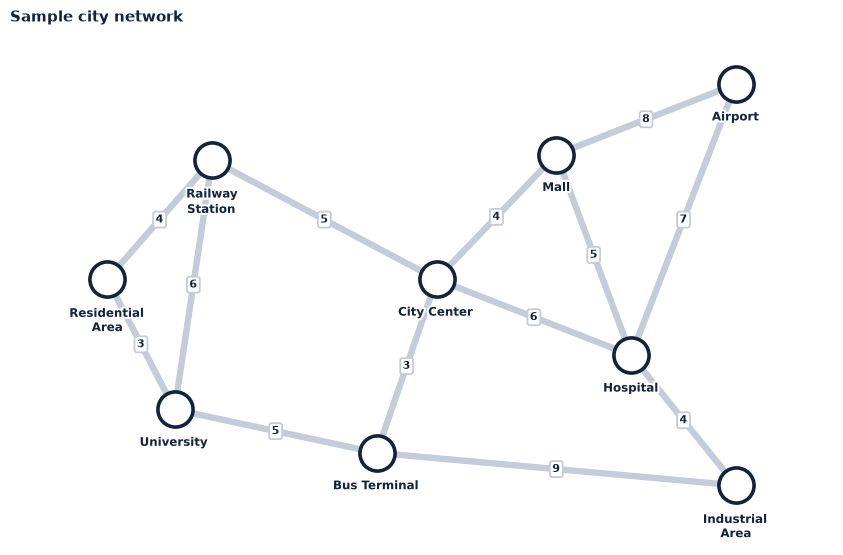

In [2]:
city = build_sample_city()
print("Intersections:", city.node_count)
print("Roads        :", city.edge_count)
fig = draw_network(city, title="Sample city network")
plt.show()

## 2. Adjacency list and adjacency matrix
Both describe the same graph. The matrix is built *from* the same data, so it always matches the list.

In [3]:
for node, neighbours in city.adjacency_list().items():
    print(f"{node}:")
    for nb, cost in neighbours:
        print(f"   - {nb}: {cost}")

City Center:
   - Mall: 4
   - Hospital: 6
   - Railway Station: 5
   - Bus Terminal: 3
Airport:
   - Mall: 8
   - Hospital: 7
Railway Station:
   - City Center: 5
   - University: 6
   - Residential Area: 4
University:
   - Railway Station: 6
   - Residential Area: 3
   - Bus Terminal: 5
Hospital:
   - City Center: 6
   - Mall: 5
   - Airport: 7
   - Industrial Area: 4
Mall:
   - City Center: 4
   - Airport: 8
   - Hospital: 5
Bus Terminal:
   - City Center: 3
   - University: 5
   - Industrial Area: 9
Industrial Area:
   - Hospital: 4
   - Bus Terminal: 9
Residential Area:
   - Railway Station: 4
   - University: 3


In [4]:
print(city.adjacency_matrix().to_string())

                  City Center  Airport  Railway Station  University  Hospital  Mall  Bus Terminal  Industrial Area  Residential Area
City Center                 0        0                5           0         6     4             3                0                 0
Airport                     0        0                0           0         7     8             0                0                 0
Railway Station             5        0                0           6         0     0             0                0                 4
University                  0        0                6           0         0     0             5                0                 3
Hospital                    6        7                0           0         0     5             0                4                 0
Mall                        4        8                0           0         5     0             0                0                 0
Bus Terminal                3        0                0           5  

## 3. Dijkstra - shortest route
Greedy algorithm: repeatedly lock the closest unfinished intersection, then *relax* its roads.
Requires non-negative costs.

In [5]:
run = dijkstra(city.adj, "City Center")
route = find_route(city.adj, "City Center", "Airport", "Dijkstra")
print(" -> ".join(route["path"]))
print("Total cost:", route["cost"])
print()
for step in route["run"]["steps"][:4]:
    print(f"Step {step['step']}: settle {step['node']} (distance {step['distance']})")
    for r in step["relaxations"]:
        flag = "updated" if r["updated"] else "no change"
        print(f"     {r['neighbor']:<18} best so far {r['old_distance']!s:>4}  via here {r['new_distance']:>3}  -> {flag}")

City Center -> Mall -> Airport
Total cost: 12

Step 1: settle City Center (distance 0)
     Mall               best so far  inf  via here   4  -> updated
     Hospital           best so far  inf  via here   6  -> updated
     Railway Station    best so far  inf  via here   5  -> updated
     Bus Terminal       best so far  inf  via here   3  -> updated
Step 2: settle Bus Terminal (distance 3)
     University         best so far  inf  via here   8  -> updated
     Industrial Area    best so far  inf  via here  12  -> updated
Step 3: settle Mall (distance 4)
     Airport            best so far  inf  via here  12  -> updated
     Hospital           best so far    6  via here   9  -> no change
Step 4: settle Railway Station (distance 5)
     University         best so far    8  via here  11  -> no change
     Residential Area   best so far  inf  via here   9  -> updated


## 4. Bellman-Ford - same question, different method
Relax **every** road, V-1 times. Slower, but it also works with negative costs and detects negative cycles.

In [6]:
bf = find_route(city.adj, "City Center", "Airport", "Bellman-Ford")
print(" -> ".join(bf["path"]), "| cost", bf["cost"])
print("Passes needed (stops early when nothing changes):", len(bf["run"]["passes"]))
print("Same cost as Dijkstra:", bf["cost"] == route["cost"])

City Center -> Mall -> Airport | cost 12
Passes needed (stops early when nothing changes): 2
Same cost as Dijkstra: True


## 5. Traffic congestion (Bellman-Ford)
We slow the *City Center - Mall* road from 4 to 15 and compare the best route before and after.
The original network is never modified - we analyse a modified **copy**.

Original route : City Center -> Mall -> Airport | cost 12
Updated route  : City Center -> Hospital -> Airport | cost 13
Cost difference: 1 (8.3%)
If we stayed on the old route it would cost: 23
Detour saves   : 10
Trips made slower network-wide: 10 of 36


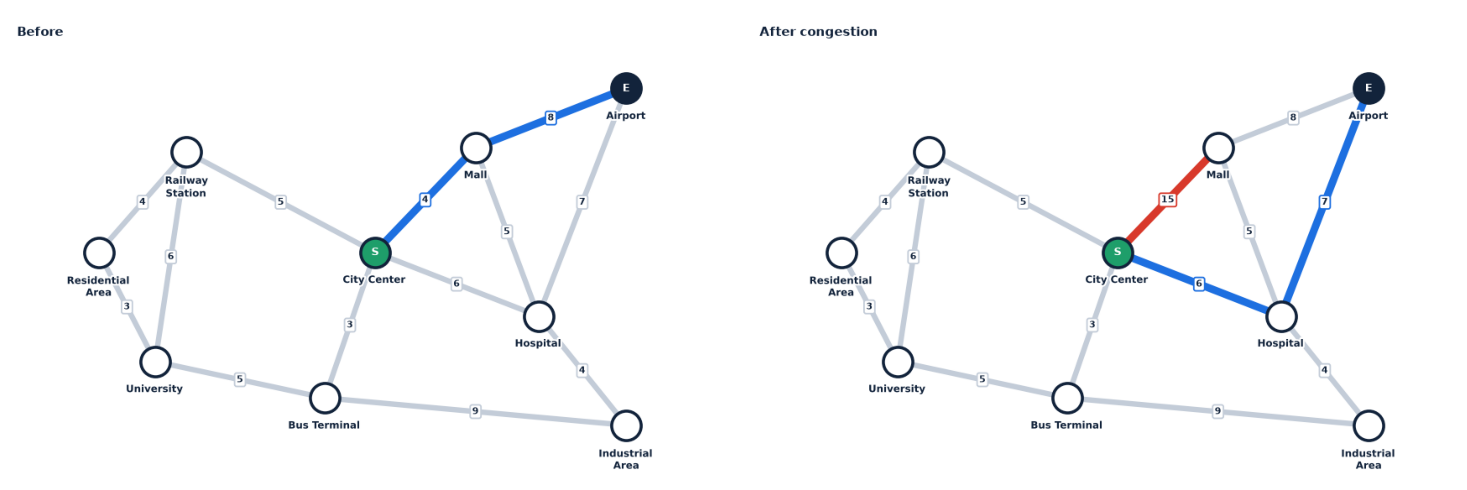

In [7]:
res = analyze_congestion(city, {("City Center", "Mall"): 15}, "City Center", "Airport")
print("Original route :", " -> ".join(res["path_before"]), "| cost", res["cost_before"])
print("Updated route  :", " -> ".join(res["path_after"]),  "| cost", res["cost_after"])
print("Cost difference:", res["extra_cost"], f"({res['extra_pct']:.1f}%)")
print("If we stayed on the old route it would cost:", res["stay_cost"])
print("Detour saves   :", res["detour_saving"])
print("Trips made slower network-wide:", res["impact"]["affected"], "of", res["impact"]["pairs"])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (net, path, ttl, cong) in zip(axes, [(city, res["path_before"], "Before", {}),
                                             (res["congested"], res["path_after"], "After congestion", {("City Center","Mall"): 15/4})]):
    f = draw_network(net, route=path, congestion=cong, title=ttl, start="City Center", end="Airport")
    f.canvas.draw(); ax.imshow(f.canvas.buffer_rgba()); ax.axis("off"); plt.close(f)
plt.tight_layout(); plt.show()

## 6. BFS and DFS
BFS uses a **queue** (level by level); DFS uses a **stack** (deep first). Neighbours are visited alphabetically so results are repeatable.

In [8]:
b, d = bfs(city.adj, "City Center"), dfs(city.adj, "City Center")
print("BFS:", " -> ".join(b["order"]))
print("DFS:", " -> ".join(d["order"]))
print("Reachable from City Center:", len(b["order"]), "of", city.node_count)
print("Separate areas in the network:", len(connected_components(city.adj)))

BFS: City Center -> Bus Terminal -> Hospital -> Mall -> Railway Station -> Industrial Area -> University -> Airport -> Residential Area
DFS: City Center -> Bus Terminal -> Industrial Area -> Hospital -> Airport -> Mall -> University -> Railway Station -> Residential Area
Reachable from City Center: 9 of 9
Separate areas in the network: 1


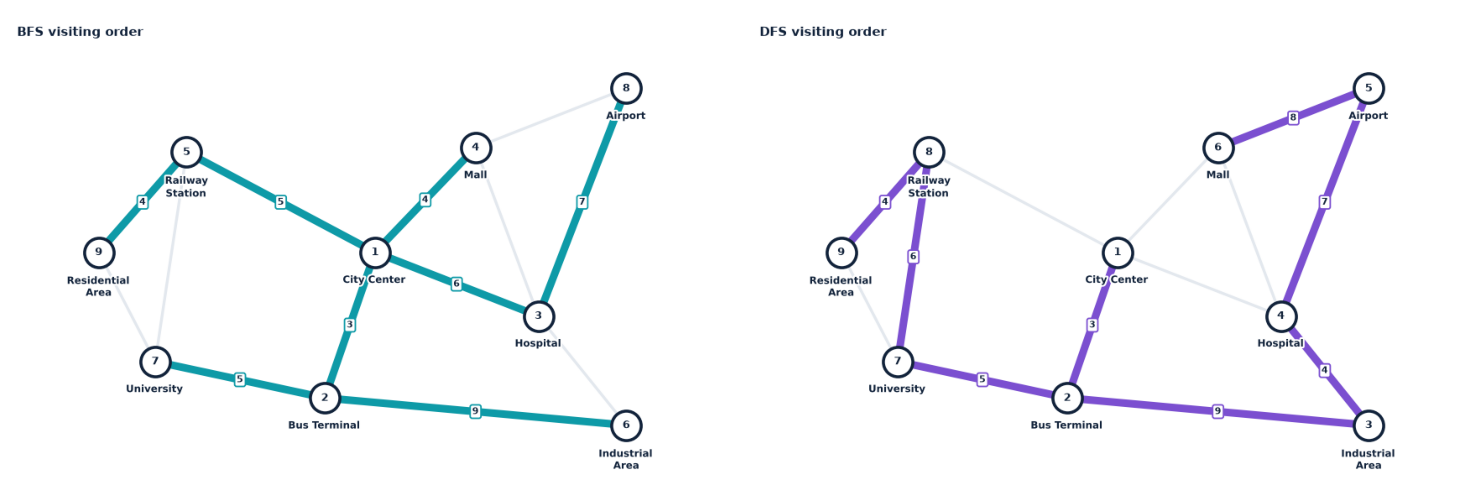

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, result, color, name in zip(axes, (b, d), (COLORS["teal"], COLORS["violet"]), ("BFS", "DFS")):
    f = draw_network(city, highlight_edges=result["tree_edges"], highlight_color=color, dim_others=True,
                     badges={n: str(i + 1) for i, n in enumerate(result["order"])}, title=f"{name} visiting order")
    f.canvas.draw(); ax.imshow(f.canvas.buffer_rgba()); ax.axis("off"); plt.close(f)
plt.tight_layout(); plt.show()

## 7. Minimum spanning tree - Prim and Kruskal
The cheapest set of roads that still connects every intersection (exactly V-1 roads, no loops).

In [10]:
p, k = prim(city.adj, "City Center"), kruskal(city.adj)
for r in (p, k):
    print(f"{r['algorithm']}: total cost {r['total_cost']} using {len(r['edges'])} roads")
    for u, v, w in r["edges"]:
        print(f"    {u} - {v}: {w}")
print("Same total cost:", p["total_cost"] == k["total_cost"])
print("Cost of building ALL roads:", sum(w for _, _, w in city.edges()))

Prim: total cost 35 using 8 roads
    City Center - Bus Terminal: 3
    City Center - Mall: 4
    Bus Terminal - University: 5
    University - Residential Area: 3
    Residential Area - Railway Station: 4
    Mall - Hospital: 5
    Hospital - Industrial Area: 4
    Hospital - Airport: 7
Kruskal: total cost 35 using 8 roads
    City Center - Bus Terminal: 3
    University - Residential Area: 3
    City Center - Mall: 4
    Hospital - Industrial Area: 4
    Railway Station - Residential Area: 4
    City Center - Railway Station: 5
    Hospital - Mall: 5
    Airport - Hospital: 7
Same total cost: True
Cost of building ALL roads: 69


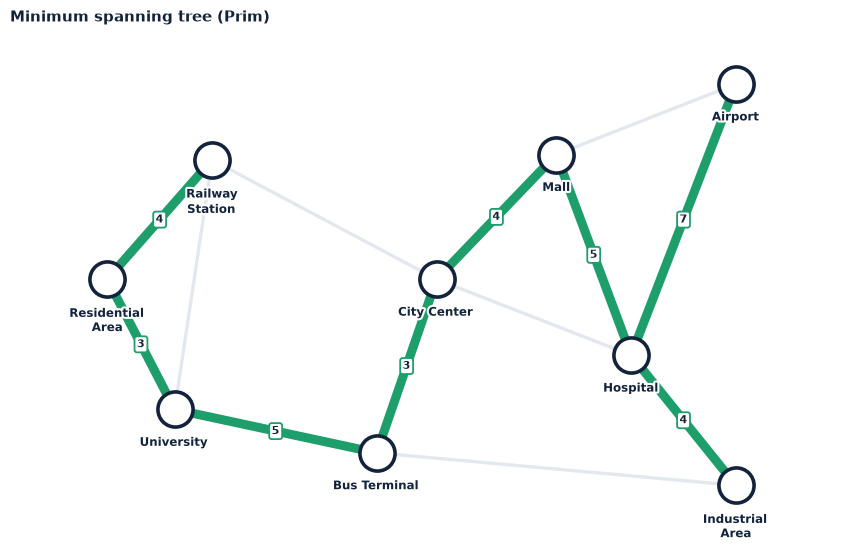

In [11]:
f = draw_network(city, highlight_edges=[(u, v) for u, v, _ in p["edges"]], highlight_color=COLORS["green"],
                 dim_others=True, title="Minimum spanning tree (Prim)")
plt.show()

## 8. Experiments on larger networks
Random connected networks of 10, 25, 50 and 100 intersections. Each algorithm is timed by repeating it many times and
averaging (`time.perf_counter`); peak memory comes from `tracemalloc`. **These numbers were measured when this notebook was run, they are not typed in.**

In [12]:
df = benchmark.run_benchmark(seed=42, min_seconds=0.1)
print(df.pivot(index="Intersections", columns="Algorithm", values="Time (ms)")[benchmark.ALGORITHMS].round(4).to_string())
print()
print("Peak memory (KB):")
print(df.pivot(index="Intersections", columns="Algorithm", values="Peak memory (KB)")[benchmark.ALGORITHMS].round(1).to_string())
print()
print(benchmark.agreement_report(df).to_string(index=False))

Algorithm         BFS     DFS  Dijkstra  Bellman-Ford    Prim  Kruskal
Intersections                                                         
10             0.0083  0.0107    0.0103        0.0328  0.0117   0.0257
25             0.0204  0.0260    0.0300        0.1217  0.0406   0.0535
50             0.0389  0.0501    0.0602        0.2799  0.0656   0.1393
100            0.0793  0.1041    0.1234        0.5724  0.1596   0.3134

Peak memory (KB):
Algorithm       BFS   DFS  Dijkstra  Bellman-Ford  Prim  Kruskal
Intersections                                                   
10              2.3   1.6       1.3           1.2   1.2      3.0
25              5.1   4.5       4.3           2.8   3.1      3.0
50              6.9   6.8       5.9           5.4   3.4     10.9
100            17.8  17.8      17.0          11.1  11.8     10.9

 Intersections  Dijkstra = Bellman-Ford  Prim = Kruskal
            10                     True            True
            25                     True            T

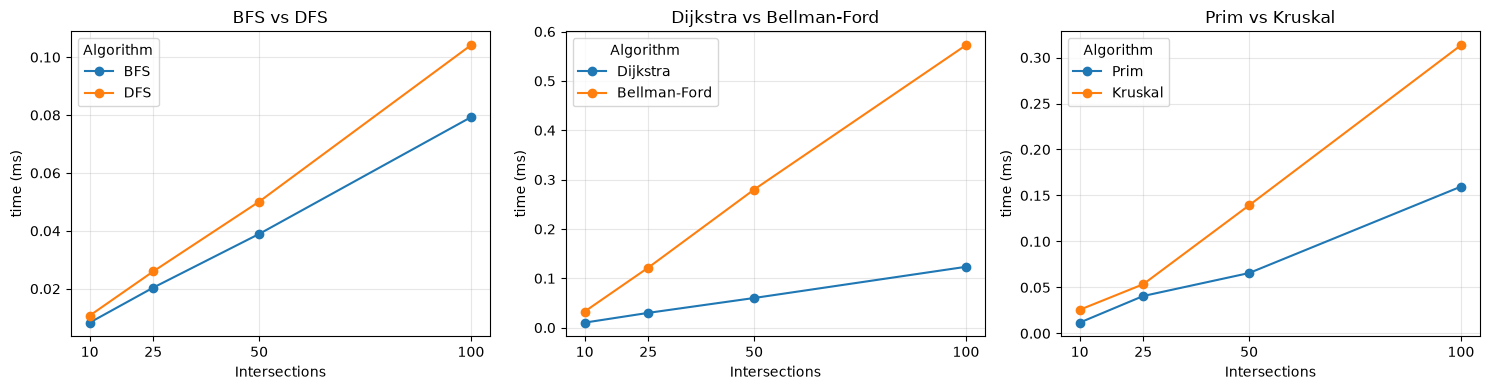

In [13]:
pivot = df.pivot(index="Intersections", columns="Algorithm", values="Time (ms)")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, pair in zip(axes, (["BFS", "DFS"], ["Dijkstra", "Bellman-Ford"], ["Prim", "Kruskal"])):
    pivot[pair].plot(ax=ax, marker="o")
    ax.set_title(" vs ".join(pair)); ax.set_ylabel("time (ms)"); ax.set_xticks(pivot.index); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

In [14]:
print(df[df["Intersections"] == 100][["Algorithm", "Roads in result", "Cost of result"]].to_string(index=False))

   Algorithm  Roads in result  Cost of result
         BFS                3              30
         DFS               17             160
    Dijkstra                5              23
Bellman-Ford                5              23
        Prim               99             632
     Kruskal               99             632


## 9. Conclusions
* **BFS vs DFS** - both O(V+E). BFS finds the path with the fewest roads; DFS's path is usually much longer (see the last table). Use BFS for "nearest", DFS for connectivity / component questions.
* **Dijkstra vs Bellman-Ford** - both found identical route costs on every network. Dijkstra is faster in theory *and* in the measurements; Bellman-Ford is the one to use when costs can be negative or you must detect negative cycles.
* **Prim vs Kruskal** - both produced MSTs with identical total cost on every network; only the way they build the tree differs.
* All results were cross-checked against `networkx` in `tests/test_algorithms.py`.